# DSP Lab 2: 10-Word Speech Recognition

# 1. Dataset Preparation

Prepare a speech dataset containing 10 distinct spoken words. You may use an existing speech dataset or
create your own dataset by recording the selected words.

## Option B: Self-recorded dataset

Create your own dataset using recordings from at least 5 different speakers. Each speaker should
pronounce each of the 10 selected words at least 5 times.
Try to keep the recording conditions and audio format consistent across speakers.

**Training and test data**

Divide the dataset into training and test sets using a speaker-independent split:
- Recordings from the same speaker must not appear in both the training and test sets.
- Make sure that all selected words are represented in both the training and test sets.

In [1]:
import os
import shutil

raw_folder = "dataset"

out_folder = "dataset_split"

# 5 speakers for training, 2 speakers for testing
train_speakers = ["spk01", "spk02", "spk03", "spk04", "spk05"]
test_speakers  = ["spk06", "spk07"]

train_folder = os.path.join(out_folder, "train")
test_folder  = os.path.join(out_folder, "test")
os.makedirs(train_folder, exist_ok=True)
os.makedirs(test_folder, exist_ok=True)

train_count = 0
test_count = 0

# os.walk looks inside all subfolders
for folder, subfolders, files in os.walk(raw_folder):
    for filename in files:
        if not filename.endswith(".wav"):
            continue

        speaker = filename.split("_")[0]    # e.g. "spk01"
        source = os.path.join(folder, filename)

        if speaker in train_speakers:
            shutil.copy(source, os.path.join(train_folder, filename))
            train_count += 1
        elif speaker in test_speakers:
            shutil.copy(source, os.path.join(test_folder, filename))
            test_count += 1

print("Train files:", train_count)
print("Test files:", test_count)

Train files: 250
Test files: 100


In [2]:
import os
import wave

root = "dataset_split"

speakers = set()
words = {}
rates = set()
channels = set()
durations = []

for folder, subfolders, files in os.walk(root):
    for filename in files:
        if not filename.endswith(".wav"):
            continue
        parts = filename[:-4].split("_")      # spk01, atgal, 01
        speakers.add(parts[0])
        words[parts[1]] = words.get(parts[1], 0) + 1

        w = wave.open(os.path.join(folder, filename))
        rates.add(w.getframerate())
        channels.add(w.getnchannels())
        durations.append(w.getnframes() / w.getframerate())
        w.close()

print("Speakers:", sorted(speakers))
print("Number of speakers:", len(speakers))
print("Recordings:", len(durations))
print("Number of words:", len(words))
print("Recordings per word:", words)
print("Sampling rates:", rates)
print("Channels:", channels)

if durations:
    print("Shortest:", round(min(durations), 2), "s")
    print("Longest: ", round(max(durations), 2), "s")
    print("Average: ", round(sum(durations) / len(durations), 2), "s")

Speakers: ['spk01', 'spk02', 'spk03', 'spk04', 'spk05', 'spk06', 'spk07']
Number of speakers: 7
Recordings: 350
Number of words: 10
Recordings per word: {'atgal': 35, 'desine': 35, 'du': 35, 'kaire': 35, 'ne': 35, 'pirmyn': 35, 'stop': 35, 'taip': 35, 'trys': 35, 'vienas': 35}
Sampling rates: {48000}
Channels: {1}
Shortest: 0.34 s
Longest:  1.47 s
Average:  0.82 s


# 2. Feature Extraction

Before feature extraction, ensure that all audio recordings have the same sampling frequency and consistent
signal duration. If necessary, apply appropriate padding.

Specify the parameters used for feature extraction, including: frame/window length, frame shift (hop
length), window function, FFT size, number of mel filters (if a mel-based representation is used).

Convert the audio recordings into a feature representation suitable for speech recognition. Choose one
feature representation (e.g., a spectrogram or log-mel spectrogram) and use the same representation and
extraction parameters for all recordings.

In [3]:
import os
import re
import numpy as np
import librosa

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------
root = r"dataset"   #
test_speakers = ["spk02"]                       # later: ["spk05"]

# Feature extraction parameters (same for ALL recordings)
SR = 16000            # sampling frequency (Hz)
DURATION = 1.0        # signal length (seconds)
N_SAMPLES = int(SR * DURATION)   # 16000 samples

WIN_LENGTH = 400      # frame length: 400 samples = 25 ms
HOP_LENGTH = 160      # frame shift:  160 samples = 10 ms
N_FFT = 512           # FFT size
WINDOW = "hann"       # window function
N_MELS = 40           # number of mel filters
FMIN = 0              # lowest frequency (Hz)
FMAX = 8000           # highest frequency (Hz) = SR / 2

# ------------------------------------------------------------
# 2. SPLIT BY SPEAKER (same as before)
# ------------------------------------------------------------
train = []
test = []

for folder, subfolders, files in os.walk(root):
    word = os.path.basename(folder)
    for file in files:
        if not re.match(r"^spk\d+_[a-z]+_\d+\.wav$", file):
            continue
        path = os.path.join(folder, file)
        speaker = file.split("_")[0]
        if speaker in test_speakers:
            test.append((path, word))
        else:
            train.append((path, word))

words = sorted(set(w for p, w in train + test))
word_to_id = {w: i for i, w in enumerate(words)}
print("Words:", words)


# ------------------------------------------------------------
# 3. FEATURE EXTRACTION FUNCTION
# ------------------------------------------------------------
def extract_features(path):
    # load: resamples to 16 kHz and converts to mono
    signal, _ = librosa.load(path, sr=SR, mono=True)

    # make the length exactly 1 second
    if len(signal) > N_SAMPLES:
        signal = signal[:N_SAMPLES]                      # cut
    else:
        signal = np.pad(signal, (0, N_SAMPLES - len(signal)))  # zero padding

    # mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=signal, sr=SR,
        n_fft=N_FFT, win_length=WIN_LENGTH, hop_length=HOP_LENGTH,
        window=WINDOW, n_mels=N_MELS, fmin=FMIN, fmax=FMAX,
    )

    # log (in dB)
    log_mel = librosa.power_to_db(mel, ref=np.max)
    return log_mel          # shape: (40, 101)


def make_dataset(file_list):
    X = []
    y = []
    for path, word in file_list:
        X.append(extract_features(path))
        y.append(word_to_id[word])
    return np.array(X), np.array(y)


# ------------------------------------------------------------
# 4. RUN
# ------------------------------------------------------------
X_train, y_train = make_dataset(train)
X_test, y_test = make_dataset(test)

print("X_train shape:", X_train.shape)   # (files, 40, 101)
print("X_test shape: ", X_test.shape)

# save so you don't need to extract again
np.savez("features.npz", X_train=X_train, y_train=y_train,
         X_test=X_test, y_test=y_test, words=words)
print("Saved to features.npz")

Words: ['atgal', 'desine', 'du', 'kaire', 'ne', 'pirmyn', 'stop', 'taip', 'trys', 'vienas']
X_train shape: (300, 40, 101)
X_test shape:  (50, 40, 101)
Saved to features.npz


In [4]:
import os
import numpy as np
import librosa

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------
train_folder = os.path.join("dataset_split", "train")
test_folder = os.path.join("dataset_split", "test")

# Feature extraction parameters (same for ALL recordings)
SR = 16000            # sampling frequency (Hz)
DURATION = 1.0       # signal length (seconds)
N_SAMPLES = int(SR * DURATION)   # 24000 samples

WIN_LENGTH = 400      # frame length: 400 samples = 25 ms
HOP_LENGTH = 160      # frame shift:  160 samples = 10 ms
N_FFT = 512           # FFT size
WINDOW = "hann"       # window function
N_MELS = 40           # number of mel filters
FMIN = 0              # lowest frequency (Hz)
FMAX = 8000           # highest frequency (Hz) = SR / 2


# ------------------------------------------------------------
# 2. LIST FILES (word is the 2nd part of the file name)
#    spk01_atgal_01.wav -> speaker "spk01", word "atgal"
# ------------------------------------------------------------
def list_files(folder):
    items = []
    for filename in sorted(os.listdir(folder)):
        if filename.startswith(".") or not filename.lower().endswith(".wav"):
            continue
        word = filename.split("_")[1]
        items.append((os.path.join(folder, filename), word))
    return items


train = list_files(train_folder)
test = list_files(test_folder)

words = sorted(set(w for p, w in train + test))
word_to_id = {w: i for i, w in enumerate(words)}
print("Words:", words)
print("Train files:", len(train), "| Test files:", len(test))


# ------------------------------------------------------------
# 3. FEATURE EXTRACTION
# ------------------------------------------------------------
def extract_features(path):
    # load: converts to mono and resamples (e.g. 48 kHz -> 16 kHz)
    signal, _ = librosa.load(path, sr=SR, mono=True)

    # make the length exactly 1.0 s
    if len(signal) > N_SAMPLES:
        signal = signal[:N_SAMPLES]                              # cut
    else:
        signal = np.pad(signal, (0, N_SAMPLES - len(signal)))    # zero padding

    # mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=signal, sr=SR,
        n_fft=N_FFT, win_length=WIN_LENGTH, hop_length=HOP_LENGTH,
        window=WINDOW, n_mels=N_MELS, fmin=FMIN, fmax=FMAX,
    )

    # log scale (dB)
    return librosa.power_to_db(mel, ref=np.max)    # shape: (40, 151)


def make_dataset(file_list):
    X = [extract_features(path) for path, word in file_list]
    y = [word_to_id[word] for path, word in file_list]
    return np.array(X), np.array(y)


# ------------------------------------------------------------
# 4. RUN AND SAVE
# ------------------------------------------------------------
X_train, y_train = make_dataset(train)
X_test, y_test = make_dataset(test)

print("X_train shape:", X_train.shape)   # (files, 40, 151)
print("X_test shape: ", X_test.shape)

np.savez("features.npz", X_train=X_train, y_train=y_train,
         X_test=X_test, y_test=y_test, words=words)
print("Saved to features.npz")

Words: ['atgal', 'desine', 'du', 'kaire', 'ne', 'pirmyn', 'stop', 'taip', 'trys', 'vienas']
Train files: 250 | Test files: 100
X_train shape: (250, 40, 101)
X_test shape:  (100, 40, 101)
Saved to features.npz


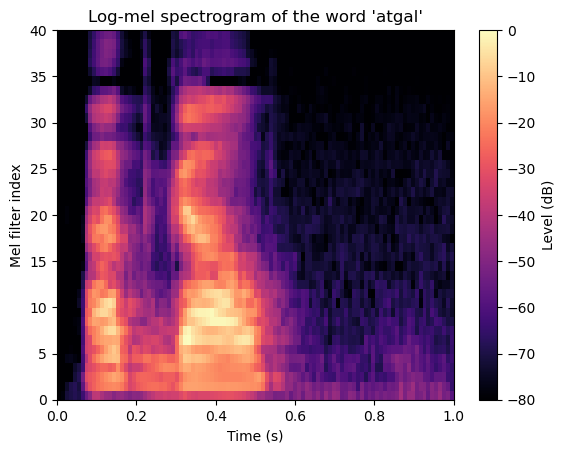

In [5]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("features.npz")
words = list(data["words"])
i = np.where(data["y_train"] == words.index("atgal"))[0][0]   # first recording of "atgal"

plt.imshow(data["X_train"][i], origin="lower", aspect="auto", cmap="magma", extent=[0, 1.0, 0, 40])
plt.colorbar(label="Level (dB)")
plt.xlabel("Time (s)")
plt.ylabel("Mel filter index")
plt.title("Log-mel spectrogram of the word 'atgal'")
plt.savefig("feature_plot.png", dpi=200)
plt.show()

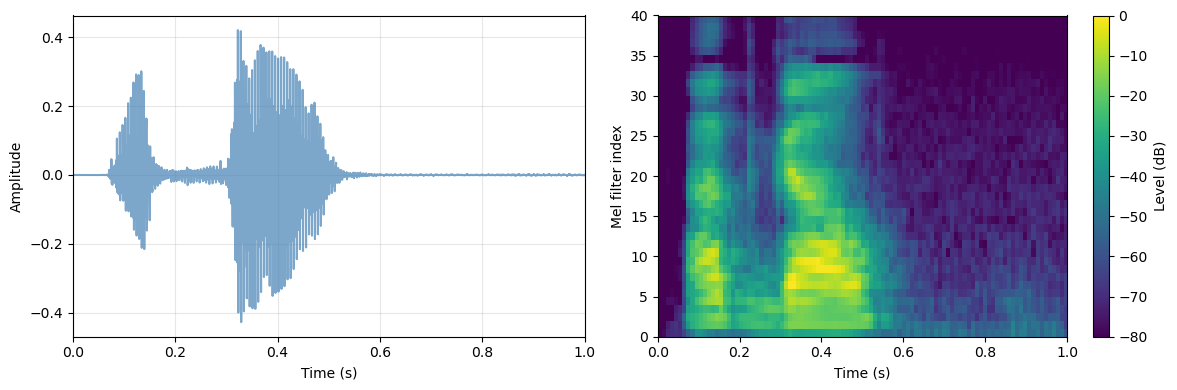

In [6]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

path = "dataset_split/train/spk01_atgal_01.wav"

# Load audio: 16 kHz, mono, exactly 1 second
signal, sr = librosa.load(path, sr=16000, mono=True)
signal = np.pad(signal, (0, max(0, 16000 - len(signal))))[:16000]

# Compute log-mel spectrogram
mel = librosa.feature.melspectrogram(
    y=signal,
    sr=16000,
    n_fft=512,
    win_length=400,
    hop_length=160,
    window="hann",
    n_mels=40,
    fmax=8000
)
log_mel = librosa.power_to_db(mel, ref=np.max)

# Side-by-side plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Waveform
time = np.arange(len(signal)) / 16000
ax1.plot(time, signal, color="steelblue", alpha=0.7)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Amplitude")
#ax1.set_title("Waveform of 'atgal'")
ax1.set_xlim(0, 1.0)
ax1.set_axisbelow(True)
ax1.grid(True, alpha=0.3)

# Log-mel spectrogram
img = ax2.imshow(
    log_mel,
    origin="lower",
    aspect="auto",
    cmap="viridis",
    extent=[0, 1.0, 0, 40]
)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Mel filter index")
#ax2.set_title("Log-mel Spectrogram")

fig.colorbar(img, ax=ax2, label="Level (dB)")

plt.tight_layout()
plt.savefig("waveform_and_feature.pdf", dpi=200, bbox_inches="tight")
plt.show()

# 3. Model selection

Use a single fixed model architecture throughout all experiments. The purpose of the model is to provide a
consistent baseline for evaluating the effect of different noise conditions, rather than to optimize the model
architecture.

A simple Convolutional Neural Network (CNN) is recommended for spectrogram or log-mel spectrogram
input.

Use the speaker-independent training and test split defined during dataset preparation.

In [7]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

# ------------------------------------------------------------
# 1. FIXED SETTINGS (do not change between experiments)
# ------------------------------------------------------------
SEED = 42
EPOCHS = 30
BATCH_SIZE = 16
LEARNING_RATE = 0.001

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# 2. LOAD FEATURES (speaker-independent split from features.npz)
# ------------------------------------------------------------
data = np.load("features.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]
words = list(data["words"])

# normalize using TRAIN mean and std only
mean = X_train.mean()
std = X_train.std()
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# add channel dimension: (files, 40, 151) -> (files, 40, 151, 1)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Train:", X_train.shape, "Test:", X_test.shape)


# ------------------------------------------------------------
# 3. MODEL (the same for ALL experiments)
# ------------------------------------------------------------
def build_model(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.GlobalAveragePooling2D(),

        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ])
    return model


model = build_model(X_train.shape[1:], len(words))
model.compile(
    optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# ------------------------------------------------------------
# 4. TRAIN
# ------------------------------------------------------------
model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)

# ------------------------------------------------------------
# 5. TEST
# ------------------------------------------------------------
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {acc * 100:.1f}%")

# accuracy for each word
pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print("\nAccuracy per word:")
for i, w in enumerate(words):
    mask = y_test == i
    if mask.sum() > 0:
        print(f"  {w:10s} {np.mean(pred[mask] == i) * 100:5.1f}%")

Train: (250, 40, 101, 1) Test: (100, 40, 101, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 40, 101, 16)         │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 20, 50, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 20, 50, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 10, 25, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 10, 25, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,946 (93.54 KB)

 Trainable params: 23,946 (93.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
16/16 - 13s - 802ms/step - accuracy: 0.1400 - loss: 2.3014
Epoch 2/30
16/16 - 1s - 37ms/step - accuracy: 0.1720 - loss: 2.2537
Epoch 3/30
16/16 - 1s - 47ms/step - accuracy: 0.1840 - loss: 2.2086
Epoch 4/30
16/16 - 1s - 46ms/step - accuracy: 0.1760 - loss: 2.1636
Epoch 5/30
16/16 - 1s - 84ms/step - accuracy: 0.1400 - loss: 2.1449
Epoch 6/30
16/16 - 1s - 44ms/step - accuracy: 0.2160 - loss: 2.0715
Epoch 7/30
16/16 - 1s - 47ms/step - accuracy: 0.1880 - loss: 2.0128
Epoch 8/30
16/16 - 1s - 34ms/step - accuracy: 0.1880 - loss: 2.0280
Epoch 9/30
16/16 - 1s - 42ms/step - accuracy: 0.2320 - loss: 2.0382
Epoch 10/30
16/16 - 0s - 30ms/step - accuracy: 0.1800 - loss: 2.0540
Epoch 11/30
16/16 - 1s - 39ms/step - accuracy: 0.2000 - loss: 2.0028
Epoch 12/30
16/16 - 1s - 46ms/step - accuracy: 0.2120 - loss: 1.9770
Epoch 13/30
16/16 - 1s - 76ms/step - accuracy: 0.2080 - loss: 1.9763
Epoch 14/30
16/16 - 1s - 37ms/step - accuracy: 0.2160 - loss: 1.9390
Epoch 15/30
16/16 - 1s - 32ms/step - accu

# 4. Model testing

Evaluate the trained speech recognition model under different noise conditions. Apply noise only to the test
recordings; the training data should remain unchanged.

Evaluate the model under the following conditions:
1. Clean speech (original test recordings without added noise).
2. Synthetic noise (add white Gaussian noise at several SNR levels, for example 30 dB, 20 dB, 10 dB,
and 0 dB).
3. Real-world background noise (mix background noise recordings with the test speech at the same
SNR levels).

Use the same test recordings for all noise conditions so that the results can be compared directly.

In [8]:

import numpy as np
import pandas as pd

# Noise levels to test
snr_levels = [30, 20, 10, 0]

# 1. Test on clean data
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Clean speech accuracy: {accuracy * 100:.2f}%")

results = [("Clean speech", "-", accuracy * 100)]

# 2. Test with Gaussian noise
for snr in snr_levels:
    np.random.seed(42)

    # Calculate noise strength
    noise_std = np.std(X_test) / (10 ** (snr / 20))

    # Add noise ONLY to test data
    X_noisy = X_test + np.random.normal(
        0, noise_std, X_test.shape
    ).astype(np.float32)

    # Evaluate the same test recordings
    loss, accuracy = model.evaluate(
        X_noisy, y_test, verbose=0
    )

    print(f"Gaussian noise {snr} dB accuracy: {accuracy * 100:.2f}%")
    results.append(( "Gaussian noise", snr, accuracy * 100))

# 3. Save results
df = pd.DataFrame(
    results,
    columns=["Condition", "SNR (dB)", "Accuracy (%)"]
)

df.to_csv("noise_results.csv", index=False)


Clean speech accuracy: 42.00%
Gaussian noise 30 dB accuracy: 45.00%
Gaussian noise 20 dB accuracy: 43.00%
Gaussian noise 10 dB accuracy: 35.00%
Gaussian noise 0 dB accuracy: 10.00%


In [12]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

snr_levels = [30, 20, 10, 0]

# --- labels as class indices (works for one-hot or integer y_test) ---
y_true = np.argmax(y_test, axis=1) if np.ndim(y_test) > 1 else np.asarray(y_test)
n_classes = int(y_true.max()) + 1

# --- word names: use yours if you have them, otherwise indices ---
# class_names = ["yes", "no", "up", ...]      # <- your words in label order
try:
    class_names = list(class_names)
    assert len(class_names) == n_classes
except Exception:
    class_names = [str(i) for i in range(n_classes)]

def add_gaussian_noise(X, snr):
    np.random.seed(42)
    noise_std = np.std(X) / (10 ** (snr / 20))
    return X + np.random.normal(0, noise_std, X.shape).astype(np.float32)

# --- predictions and confusion matrices for every condition ---
conditions = {"Clean": X_test}
for snr in snr_levels:
    conditions[f"{snr} dB"] = add_gaussian_noise(X_test, snr)

cms = {}
for name, X in conditions.items():
    y_pred = np.argmax(model.predict(X, verbose=0), axis=1)
    cms[name] = confusion_matrix(y_true, y_pred, labels=range(n_classes))

# --- most confused word PAIRS (A->B and B->A counted together) ---
def pair_confusions(cm):
    rows = []
    for i in range(n_classes):
        for j in range(i + 1, n_classes):
            total = cm[i, j] + cm[j, i]
            if total > 0:
                rows.append((f"{class_names[i]} <-> {class_names[j]}", int(total)))
    return dict(rows)

table = pd.DataFrame({name: pair_confusions(cm) for name, cm in cms.items()}).fillna(0).astype(int)

# --- top 5 pairs in clean speech and at 0 dB ---
print("Top confused pairs, clean speech:")
print(table["Clean"].sort_values(ascending=False).head(5), "\n")

print("Top confused pairs, 0 dB SNR:")
print(table["0 dB"].sort_values(ascending=False).head(5), "\n")

# --- how each pair changes with noise (sorted by the 0 dB count) ---
top_pairs = table.sort_values("0 dB", ascending=False).head(10)
print("Confusions per condition (top 10 at 0 dB):")
print(top_pairs)

# --- which single word do predictions collapse into under noise? ---
for name, cm in cms.items():
    predicted_counts = cm.sum(axis=0)
    k = predicted_counts.argmax()
    share = predicted_counts[k] / predicted_counts.sum() * 100
    print(f"{name:>6}: most predicted word = {class_names[k]} ({share:.0f}% of all predictions)")

table.to_csv("pair_confusions.csv")

Top confused pairs, clean speech:
2 <-> 4    6
0 <-> 1    5
6 <-> 7    5
0 <-> 9    4
3 <-> 9    4
Name: Clean, dtype: int32 

Top confused pairs, 0 dB SNR:
6 <-> 8    10
2 <-> 6    10
5 <-> 6    10
3 <-> 6    10
0 <-> 6    10
Name: 0 dB, dtype: int32 

Confusions per condition (top 10 at 0 dB):
         Clean  30 dB  20 dB  10 dB  0 dB
6 <-> 8      0      0      0      0    10
2 <-> 6      2      2      2      3    10
5 <-> 6      0      0      0      0    10
3 <-> 6      0      0      0      0    10
0 <-> 6      1      1      1      1    10
1 <-> 6      0      0      0      0    10
6 <-> 9      0      0      0      1    10
4 <-> 6      1      1      1      1    10
6 <-> 7      5      4      5      8    10
4 <-> 9      3      2      2      4     0
 Clean: most predicted word = 0 (24% of all predictions)
 30 dB: most predicted word = 0 (23% of all predictions)
 20 dB: most predicted word = 0 (25% of all predictions)
 10 dB: most predicted word = 0 (25% of all predictions)
  0 dB: most 

In [9]:

from pathlib import Path
import librosa

noise_folder = Path("STRAFFIC_16k")
noise_files = sorted(noise_folder.rglob("*.wav"))

if not noise_files:
    raise FileNotFoundError(
        "No WAV files found. Check the STRAFFIC_16k folder path."
    )

print("Number of traffic recordings:", len(noise_files))

# Load all traffic recordings
traffic_noises = []

for path in noise_files:
    noise, _ = librosa.load(path, sr=16000, mono=True)
    traffic_noises.append(noise)

print("Loaded", len(traffic_noises), "traffic recordings.")


Number of traffic recordings: 16
Loaded 16 traffic recordings.


In [ ]:

import numpy as np
import librosa
from pathlib import Path
from sklearn.metrics import accuracy_score

# --------------------------------------------------
# 1. Find DEMAND traffic noise recordings
# --------------------------------------------------
noise_files = sorted(Path("STRAFFIC_16k").rglob("*.wav"))

if not noise_files:
    raise FileNotFoundError("No WAV files found in STRAFFIC_16k")

print("DEMAND noise files:", len(noise_files))

# --------------------------------------------------
# 2. Mix speech with real-world background noise
# --------------------------------------------------
def mix_noise(speech, noise, snr_db):
    if len(noise) < len(speech):
        noise = np.tile(
            noise, int(np.ceil(len(speech) / len(noise)))
        )

    start = np.random.randint(0, len(noise) - len(speech) + 1)
    noise = noise[start:start + len(speech)]

    speech_power = np.mean(speech ** 2)
    noise_power = np.mean(noise ** 2)

    if speech_power < 1e-12 or noise_power < 1e-12:
        return speech.copy()

    scale = np.sqrt(
        speech_power / (noise_power * 10 ** (snr_db / 10))
    )
    return speech + scale * noise

# --------------------------------------------------
# 3. Evaluate classification accuracy
# --------------------------------------------------
np.random.seed(42)

for snr in [30, 20, 10, 0]:
    y_true, y_pred = [], []

    for path, word in test:
        # Load original test speech
        speech, _ = librosa.load(path, sr=SR, mono=True)

        # Match the original 1-second length
        speech = speech[:N_SAMPLES]
        speech = np.pad(
            speech, (0, max(0, N_SAMPLES - len(speech)))
        )

        # Try each DEMAND traffic recording
        for noise_path in noise_files:
            noise, _ = librosa.load(
                noise_path, sr=SR, mono=True
            )

            noisy = mix_noise(speech, noise, snr)

            # Extract features using your original settings
            mel = librosa.feature.melspectrogram(
                y=noisy,
                sr=SR,
                n_fft=N_FFT,
                win_length=WIN_LENGTH,
                hop_length=HOP_LENGTH,
                window=WINDOW,
                n_mels=N_MELS,
                fmin=FMIN,
                fmax=FMAX
            )

            features = librosa.power_to_db(mel, ref=np.max)

            # Match CNN input shape
            features = features[np.newaxis, ..., np.newaxis]

            # Apply the SAME training-set normalization here
            # if your model was trained using normalized features.

            prediction = model.predict(features, verbose=0)
            predicted_label = int(np.argmax(prediction[0]))

            y_true.append(word_to_id[word])
            y_pred.append(predicted_label)

    accuracy = accuracy_score(y_true, y_pred) * 100
    print(f"DEMAND traffic noise at {snr} dB SNR: {accuracy:.2f}%")


DEMAND noise files: 16
DEMAND traffic noise at 30 dB SNR: 10.00%


Audio file: dataset_split\test\spk06_atgal_01.wav


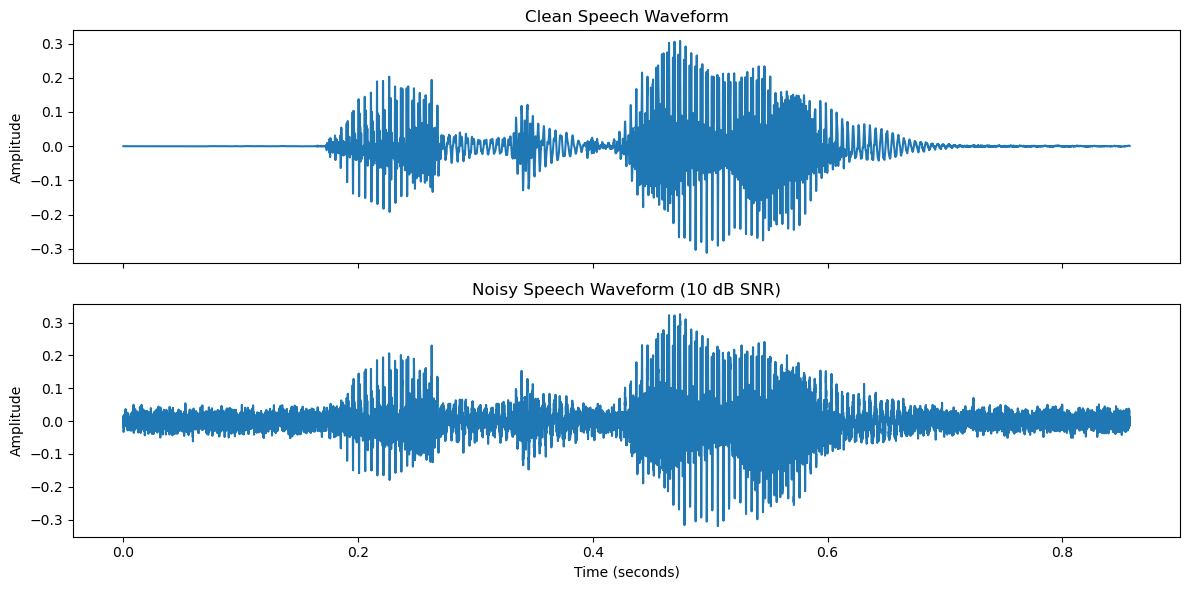

In [9]:

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load one test audio file
test_folder = Path("dataset_split/test")
audio_files = sorted(test_folder.rglob("*.wav"))

if not audio_files:
    raise FileNotFoundError("No WAV files found in dataset_split/test")

audio_path = audio_files[0]
sr = 16000

y, sr = librosa.load(audio_path, sr=sr, mono=True)
print("Audio file:", audio_path)

# 2. Add white Gaussian noise at 10 dB SNR
rng = np.random.default_rng(42)
signal_power = np.mean(y ** 2)
noise_power = signal_power / (10 ** (10 / 10))

noise = rng.normal(0, np.sqrt(noise_power), size=y.shape)
y_noisy = y + noise

# 3. Extract MFCC features
mfcc_clean = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
mfcc_noisy = librosa.feature.mfcc(y=y_noisy, sr=sr, n_mfcc=40)

# 4. Plot stacked waveforms
time = np.arange(len(y)) / sr

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax[0].plot(time, y)
ax[0].set_title("Clean Speech Waveform")
ax[0].set_ylabel("Amplitude")

ax[1].plot(time, y_noisy)
ax[1].set_title("Noisy Speech Waveform (10 dB SNR)")
ax[1].set_xlabel("Time (seconds)")
ax[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.savefig("stacked_waveforms.pdf", dpi=300)
plt.show()


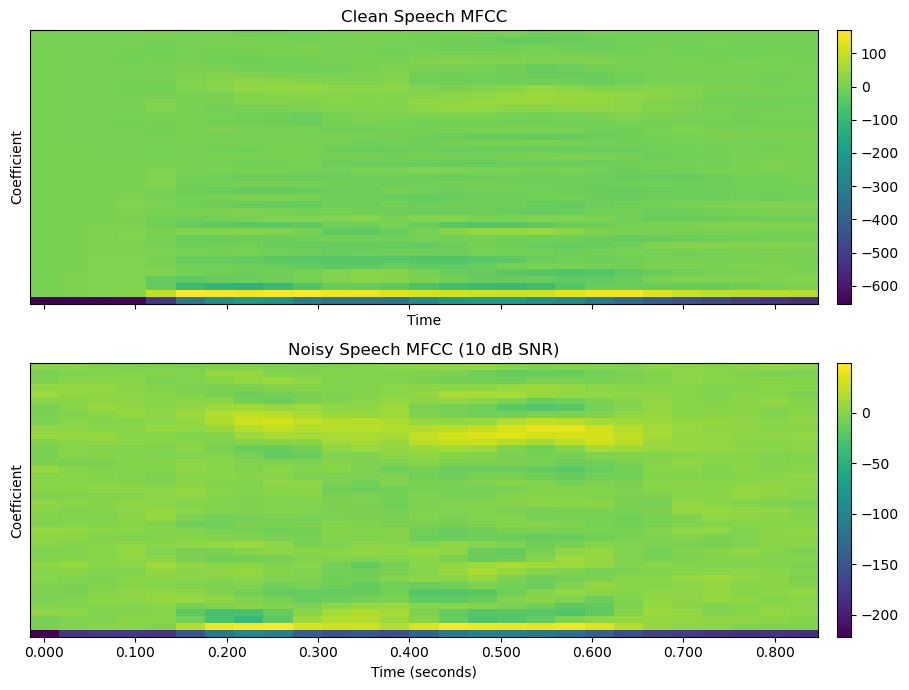

In [10]:
import librosa.display
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)

im1 = librosa.display.specshow(
    mfcc_clean, x_axis="time", sr=sr, cmap="viridis", ax=ax[0]
)
ax[0].set_title("Clean Speech MFCC")
ax[0].set_ylabel("Coefficient")
fig.colorbar(im1, ax=ax[0], pad=0.02)

im2 = librosa.display.specshow(
    mfcc_noisy, x_axis="time", sr=sr, cmap="viridis", ax=ax[1]
)
ax[1].set_title("Noisy Speech MFCC (10 dB SNR)")
ax[1].set_xlabel("Time (seconds)")
ax[1].set_ylabel("Coefficient")
fig.colorbar(im2, ax=ax[1], pad=0.02)

plt.tight_layout()
plt.savefig("side_by_side_mfcc.pdf", dpi=300, bbox_inches="tight")
plt.show()